In [3]:
!pip install pandas scikit-learn

In [4]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [5]:

import pandas as pd

df = pd.read_csv('/content/gdrive/My Drive/Linear_regression/laptops.csv')

df.head()

,brand,model,device_category,price,rating,cpu_brand,cpu_family,cpu_series,cpu_model,cpu_suffix,...,display_height_px,display_size_inch,gpu_brand,gpu_series,gpu_model,gpu_vram_gb,gpu_type,os_name,warranty_years,Unnamed: 24
0,lenovo,Lenovo Legion Pro 5 16IAX10 83F3007CIN Gaming,Gaming,189990,84,Intel,Core Ultra,Core Ultra 7,255HX,HX,...,1600,16,NVIDIA,GeForce RTX,RTX 5060,8.0,Dedicated,Windows,1,NaN
1,lenovo,Lenovo IdeaPad Slim 3 83K100HSIN,Thin & Light,62350,54,Intel,Core,Core I5,13420H,H,...,1080,15,Intel,UHD,UHD Graphics,NaN,Integrated,Windows,1,NaN
2,asus,Asus Vivobook Go 15 E1504FA-BQ2343WS,Thin & Light,34990,51,AMD,Ryzen,Ryzen 3,7320U,U,...,1080,15,AMD,Radeon,Radeon,NaN,Integrated,Windows,1,NaN
3,lenovo,Lenovo V14 G3 82TS00JGUS,General,56990,48,Intel,Core,Core I7,1255U,U,...,1080,14,Intel,Iris Xe,Iris Xe Graphics,NaN,Integrated,Windows,1,NaN
4,dell,Dell DC 14250 ODC1425000401RINS1,General,69990,52,Intel,Core,Core 5,120U,U,...,1080,14,Intel,UHD,UHD Graphics,NaN,Integrated,Windows,1,NaN


In [6]:
print(df.shape)

(992, 25)


In [7]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 992 entries, 0 to 991
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   brand              992 non-null    object 
 1   model              992 non-null    object 
 2   device_category    992 non-null    object 
 3   price              992 non-null    int64  
 4   rating             992 non-null    int64  
 5   cpu_brand          992 non-null    object 
 6   cpu_family         992 non-null    object 
 7   cpu_series         992 non-null    object 
 8   cpu_model          992 non-null    object 
 9   cpu_suffix         861 non-null    object 
 10  cpu_core_count     992 non-null    int64  
 11  cpu_thread_count   992 non-null    int64  
 12  ram_gb             992 non-null    int64  
 13  storage_gb         992 non-null    int64  
 14  display_width_px   992 non-null    int64  
 15  display_height_px  992 non-null    int64  
 16  display_size_inch  992 non

In [8]:
df["gpu_type"].value_counts()

,count
gpu_type,
Integrated,692
Dedicated,292


In [11]:
missing_gpu = df[df["gpu_type"].isnull()]
missing_gpu

,brand,model,device_category,price,rating,cpu_brand,cpu_family,cpu_series,cpu_model,cpu_suffix,...,display_height_px,display_size_inch,gpu_brand,gpu_series,gpu_model,gpu_vram_gb,gpu_type,os_name,warranty_years,Unnamed: 24
5,dell,Dell 14 Inspiron 5440 (100UU / 16GB / 512GB / ...,General,37800,50,Intel,Core,Core I3,100U,U,...,1080,14,NaN,NaN,NaN,NaN,NaN,Windows,1,NaN
122,hp,HP ZBook Firefly 16 8F6K1PA Workstation,General,132499,62,Intel,Core,Core I7,1255U,U,...,1200,16,NaN,NaN,NaN,NaN,NaN,Windows,1,NaN
759,hp,HP ZBook Firefly 14 G10 8F6C8PA Workstation,General,132499,66,Intel,Core,Core I7,1355U,U,...,1200,14,NaN,NaN,NaN,NaN,NaN,Windows,3,NaN
765,apple,Apple 2024 MacBook Air 15,Thin & Light,104994,56,Apple,M-Series,M3,M3,NaN,...,1864,15,NaN,NaN,NaN,NaN,NaN,Mac,1,NaN
767,apple,Apple MacBook Air 15 2024,Thin & Light,154287,60,Apple,M-Series,M3,M3,NaN,...,1864,15,NaN,NaN,NaN,NaN,NaN,Mac,1,NaN
801,dell,Dell Inspiron 7440 2 in 1,Convertible,75990,62,Intel,Core,Core I5,1334U,U,...,1080,14,NaN,NaN,NaN,NaN,NaN,Windows,1,NaN
822,dell,Dell 14 Inspiron 7440 2in1,General,85512,64,Intel,Core,Core 7,150U,U,...,1400,14,NaN,NaN,NaN,NaN,NaN,Windows,1,NaN
843,dell,Dell Inspiron 7440 2in1,General,61990,56,Intel,Core,Core 3,100U,U,...,1400,14,NaN,NaN,NaN,NaN,NaN,Windows,1,NaN


In [13]:
df_cleaned = df.dropna(subset=["gpu_type"])

In [14]:
df_cleaned.shape

(984, 25)

In [15]:
gpu_vram_gb = df_cleaned["gpu_vram_gb"]

In [18]:
gpu_vram_gb.unique()

array([ 8., nan,  6., 24., 16.,  4., 12.,  2.])

In [20]:
gpu_vram_gb.value_counts()

,count
gpu_vram_gb,
6.0,92
8.0,87
4.0,81
12.0,15
16.0,11
24.0,5
2.0,1


In [21]:
features = [
    "cpu_core_count",
    "cpu_thread_count",
    "ram_gb",
    "storage_gb",
    "gpu_type",
    "gpu_model",
]

X = df_cleaned[features]

y = df_cleaned['price']

In [22]:
X.head()

,cpu_core_count,cpu_thread_count,ram_gb,storage_gb,gpu_type,gpu_model
0,20,20,32,1024,Dedicated,RTX 5060
1,8,12,16,1024,Integrated,UHD Graphics
2,4,8,16,512,Integrated,Radeon
3,10,12,16,512,Integrated,Iris Xe Graphics
4,10,12,16,512,Integrated,UHD Graphics


In [23]:
y.head()

,price
0,189990
1,62350
2,34990
3,56990
4,69990


In [24]:
print("Missing values in each feature:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())

Missing values in each feature:
cpu_core_count      0
cpu_thread_count    0
ram_gb              0
storage_gb          0
gpu_type            0
gpu_model           0
dtype: int64

Total missing values: 0


In [26]:
numerical_features = [
    "cpu_core_count",
    "cpu_thread_count",
    "ram_gb",
    "storage_gb"
]


categorical_features = [
    "gpu_type",
    "gpu_model"
]

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


# Transform categorical features into numerical columns
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (787, 6)
Testing features: (197, 6)
Training target: (787,)
Testing target: (197,)


In [34]:
from sklearn.linear_model import LinearRegression
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

In [35]:
model.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


In [37]:
y_pred = model.predict(X_test)

In [40]:

print("Actual prices:")
print(y_test.head(10).to_list())

print("\nPredicted prices:")
print(y_pred[:10].round(2))

Actual prices:
[34750, 68475, 210990, 79990, 75990, 288490, 89999, 55900, 35190, 64990]

Predicted prices:
[ 34349.72  71077.33 137881.2   73382.6   81649.74 196162.69 112816.9
  60129.69  39820.74  89801.27]


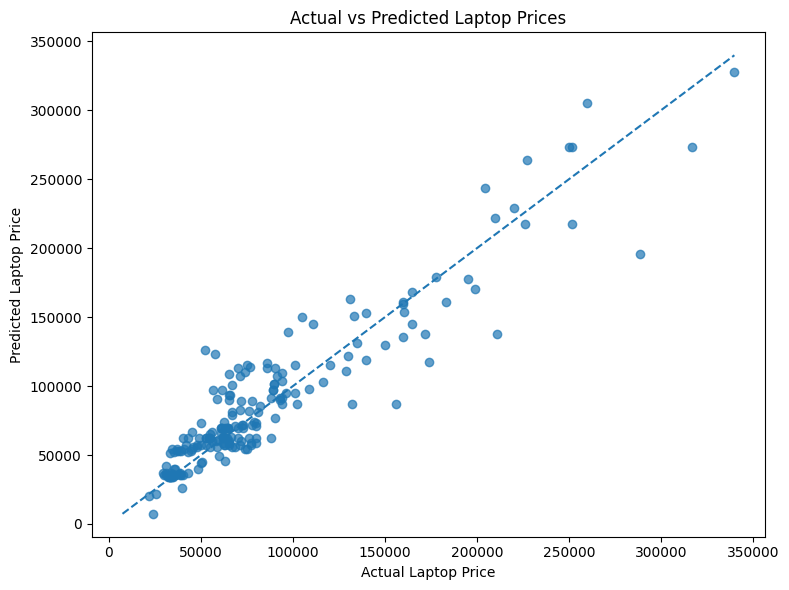

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line: perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Laptop Price")
plt.ylabel("Predicted Laptop Price")
plt.title("Actual vs Predicted Laptop Prices")

plt.tight_layout()
plt.show()

In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 14557.09
Mean Squared Error (MSE): 447532665.84
R² Score: 0.8672


In [43]:
features = [
    "brand",
    "cpu_core_count",
    "cpu_thread_count",
    "cpu_model",
    "ram_gb",
    "storage_gb",
    "gpu_type",
    "gpu_model",
    "display_size_inch",
    "display_width_px",
    "display_height_px",
    "device_category"
]

X = df_cleaned[features]
y = df_cleaned["price"]

In [44]:
numerical_features = [
    "cpu_core_count",
    "cpu_thread_count",
    "ram_gb",
    "storage_gb",
    "display_size_inch",
    "display_width_px",
    "display_height_px"
]

categorical_features = [
    "brand",
    "cpu_model",
    "gpu_type",
    "gpu_model",
    "device_category"
]

In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (787, 12)
Testing features: (197, 12)
Training target: (787,)
Testing target: (197,)


In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

# Preprocessing for numerical features
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Preprocessing for categorical features
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

# Apply the correct preprocessing to each feature group
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_transformer,
            numerical_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [48]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

# Train the model
model.fit(X_train, y_train)

print("Improved Linear Regression model trained successfully.")

Improved Linear Regression model trained successfully.


In [49]:
y_pred = model.predict(X_test)

print("First 10 actual prices:")
print(y_test.head(10).to_list())

print("\nFirst 10 predicted prices:")
print(y_pred[:10])

First 10 actual prices:
[34750, 68475, 210990, 79990, 75990, 288490, 89999, 55900, 35190, 64990]

First 10 predicted prices:
[ 35071.08954716  79648.14799717 167752.60158557  46109.10637117
  77213.04491502 218347.93455153 116512.69524914  56261.02409271
  32073.12417669  88598.54808552]


Text(0.5, 1.0, 'Actual vs Predicted Laptop Prices')

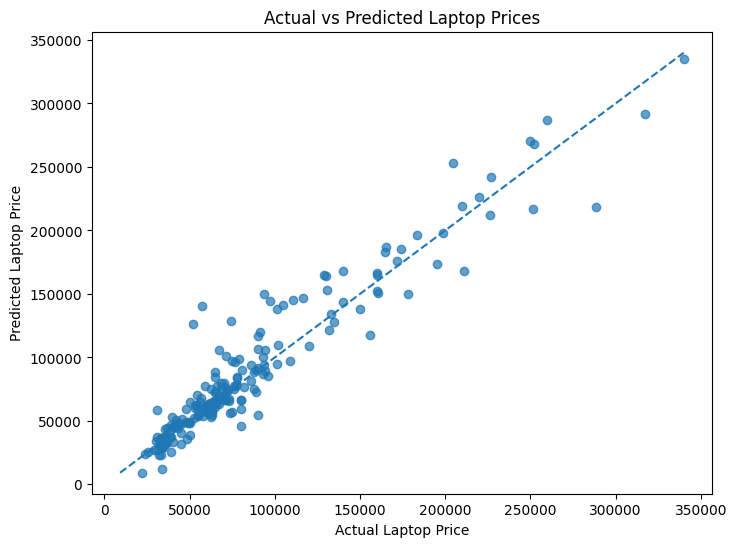

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line: perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Laptop Price")
plt.ylabel("Predicted Laptop Price")
plt.title("Actual vs Predicted Laptop Prices")

In [51]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 11488.50
Mean Squared Error (MSE): 324589182.81
Root Mean Squared Error (RMSE): 18016.36
R² Score: 0.9037
